[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/practical-molecular-dynamics-course/blob/main/notebooks/02_force_fields.ipynb)

# 02 · Force Fields Explained: Computing Every Energy Term by Hand

*Practical Molecular Dynamics Course · Hamza Hentabli, Ph.D. · ~60 min*

In Notebook 01 the potential energy was a single spring. A **force field** is the same idea for a real
molecule: a sum of simple terms for bonds, angles, torsions, van der Waals contacts, and electrostatics,
with parameters fitted to quantum chemistry and experiments. In this notebook we load **alanine dipeptide**
(Ace-Ala-NMe, the "hydrogen atom" of protein simulations) with the **AMBER ff14SB** force field in
[OpenMM](https://openmm.org), pull out every parameter, and recompute each energy term ourselves with NumPy
to check that we get exactly what OpenMM gets. After this, a force field is no longer a black box.

**Learning objectives.** By the end of this notebook you will be able to:

- write down the functional form of a class I force field (AMBER, CHARMM, OPLS, GAFF)
- load a structure into OpenMM, build a `System`, and read its forces and parameters
- recompute bond, angle, torsion, Lennard-Jones, and Coulomb energies by hand and match OpenMM
- explain exclusions and scaled 1-4 interactions, and check that forces are minus the energy gradient

In [1]:
# Setup: installs dependencies on Google Colab and locates the course data.
# Running locally? Create the environment from environment.yml once and this cell does nothing extra.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", 'openmm'], check=True)
    if not os.path.isdir("practical-molecular-dynamics-course"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/practical-molecular-dynamics-course.git"], check=True)
    DATA_DIR = "practical-molecular-dynamics-course/data"
else:
    DATA_DIR = "../data" if os.path.isdir("../data") else "data"

print("Running on Colab:", IN_COLAB, "| data folder:", DATA_DIR)

Running on Colab: False | data folder: ../data


## 1. The functional form

AMBER-type force fields write the potential energy as

$$
U = \sum_{\text{bonds}} \tfrac12 k_b (r - r_0)^2
  + \sum_{\text{angles}} \tfrac12 k_\theta (\theta - \theta_0)^2
  + \sum_{\text{torsions}} k_\phi \left[1 + \cos(n\phi - \phi_0)\right]
  + \sum_{i<j} \left( 4\varepsilon_{ij}\left[\left(\tfrac{\sigma_{ij}}{r_{ij}}\right)^{12} - \left(\tfrac{\sigma_{ij}}{r_{ij}}\right)^{6}\right]
  + \frac{q_i q_j}{4\pi\varepsilon_0 r_{ij}} \right)
$$

The first three are **bonded** terms (atoms connected by 1, 2, or 3 bonds). The last sum is **non-bonded**:
Lennard-Jones (repulsion + dispersion) and Coulomb between partial charges. Note the factor ½ in the
harmonic terms: OpenMM uses it, while AMBER parameter files fold it into $k$; mixing the two conventions
is a classic source of factor-of-two bugs.

## 2. Build an OpenMM `System`

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import openmm
from openmm import app, unit

pdb = app.PDBFile(f"{DATA_DIR}/structures/alanine_dipeptide.pdb")
ff = app.ForceField("amber14-all.xml")          # AMBER ff14SB protein force field
system = ff.createSystem(pdb.topology, nonbondedMethod=app.NoCutoff, constraints=None)

print("OpenMM", openmm.__version__, "|", pdb.topology.getNumAtoms(), "atoms,",
      pdb.topology.getNumBonds(), "bonds")
for i, f in enumerate(system.getForces()):
    f.setForceGroup(i)                           # one group per force -> per-term energies
    print(i, type(f).__name__)

OpenMM 8.6.1 | 22 atoms, 21 bonds
0 HarmonicBondForce
1 PeriodicTorsionForce
2 NonbondedForce
3 CMMotionRemover
4 HarmonicAngleForce


OpenMM turned the topology into four energy terms (plus `CMMotionRemover`, which only removes drift of the
centre of mass and has no energy). We put each in its own **force group** so we can ask OpenMM for the
energy of each term separately.

In [3]:
integrator = openmm.VerletIntegrator(0.001)
context = openmm.Context(system, integrator, openmm.Platform.getPlatformByName("Reference"))
context.setPositions(pdb.positions)

openmm_E = {}
for i, f in enumerate(system.getForces()):
    e = context.getState(getEnergy=True, groups={i}).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
    openmm_E[type(f).__name__] = e
total = context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)
pd.Series(openmm_E, name="OpenMM energy (kJ/mol)").round(4).to_frame().assign(total=round(total, 4))

,OpenMM energy (kJ/mol),total
HarmonicBondForce,0.0849,-55.761
PeriodicTorsionForce,40.3471,-55.761
NonbondedForce,-97.7280,-55.761
CMMotionRemover,0.0000,-55.761
HarmonicAngleForce,1.5350,-55.761


## 3. Atoms, types, and parameters

Each atom gets a **partial charge** $q$ and Lennard-Jones $\sigma$, $\varepsilon$ from its atom type. Positions
are in nm, energies in kJ/mol, and charges in units of the proton charge.

In [4]:
X = np.array(pdb.positions.value_in_unit(unit.nanometer))      # (22, 3) coordinates in nm
nb = [f for f in system.getForces() if isinstance(f, openmm.NonbondedForce)][0]
rows = []
for atom in pdb.topology.atoms():
    q, sig, eps = nb.getParticleParameters(atom.index)
    rows.append({"idx": atom.index, "residue": atom.residue.name, "atom": atom.name,
                 "charge": q.value_in_unit(unit.elementary_charge),
                 "sigma_nm": sig.value_in_unit(unit.nanometer),
                 "epsilon_kJmol": eps.value_in_unit(unit.kilojoule_per_mole)})
atoms = pd.DataFrame(rows)
print("net charge:", round(atoms.charge.sum(), 6))
atoms.round(4).head(12)

net charge: 0.0


,idx,residue,atom,charge,sigma_nm,epsilon_kJmol
0,0,ACE,H1,0.1123,0.2650,0.0657
1,1,ACE,CH3,-0.3662,0.3400,0.4577
2,2,ACE,H2,0.1123,0.2650,0.0657
3,3,ACE,H3,0.1123,0.2650,0.0657
4,4,ACE,C,0.5972,0.3400,0.3598
5,5,ACE,O,-0.5679,0.2960,0.8786
6,6,ALA,N,-0.4157,0.3250,0.7113
7,7,ALA,H,0.2719,0.1069,0.0657
8,8,ALA,CA,0.0337,0.3400,0.4577
9,9,ALA,HA,0.0823,0.2471,0.0657


## 4. Bonded terms by hand

In [5]:
def dist(i, j):
    return np.linalg.norm(X[i] - X[j])

def angle(i, j, k):
    a, b = X[i] - X[j], X[k] - X[j]
    return np.arccos(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)))

def dihedral(i, j, k, l):
    b0, b1, b2 = X[j] - X[i], X[k] - X[j], X[l] - X[k]
    n1, n2 = np.cross(b0, b1), np.cross(b1, b2)
    m1 = np.cross(n1, b1 / np.linalg.norm(b1))
    return np.arctan2(np.dot(m1, n2), np.dot(n1, n2))

forces = {type(f).__name__: f for f in system.getForces()}

bonds = forces["HarmonicBondForce"]
E_bond, bond_rows = 0.0, []
for b in range(bonds.getNumBonds()):
    i, j, r0, kb = bonds.getBondParameters(b)
    r0, kb = r0.value_in_unit(unit.nanometer), kb.value_in_unit(unit.kilojoule_per_mole / unit.nanometer**2)
    e = 0.5 * kb * (dist(i, j) - r0) ** 2
    E_bond += e
    bond_rows.append((atoms.atom[i] + "-" + atoms.atom[j], round(dist(i, j), 4), round(r0, 4), round(kb), round(e, 4)))

angles = forces["HarmonicAngleForce"]
E_angle = 0.0
for a in range(angles.getNumAngles()):
    i, j, k, th0, ka = angles.getAngleParameters(a)
    E_angle += 0.5 * ka.value_in_unit(unit.kilojoule_per_mole / unit.radian**2) * (angle(i, j, k) - th0.value_in_unit(unit.radian)) ** 2

tors = forces["PeriodicTorsionForce"]
E_tors = 0.0
for t in range(tors.getNumTorsions()):
    i, j, k, l, n, phi0, kt = tors.getTorsionParameters(t)
    E_tors += kt.value_in_unit(unit.kilojoule_per_mole) * (1 + np.cos(n * dihedral(i, j, k, l) - phi0.value_in_unit(unit.radian)))

print(f"{bonds.getNumBonds()} bonds, {angles.getNumAngles()} angles, {tors.getNumTorsions()} torsion terms")
for name, mine in [("HarmonicBondForce", E_bond), ("HarmonicAngleForce", E_angle), ("PeriodicTorsionForce", E_tors)]:
    print(f"{name:22s} by hand {mine:12.6f}   OpenMM {openmm_E[name]:12.6f}   diff {mine - openmm_E[name]:.1e}")
pd.DataFrame(bond_rows, columns=["bond", "r (nm)", "r0 (nm)", "k (kJ/mol/nm2)", "E (kJ/mol)"]).head(8)

21 bonds, 36 angles, 42 torsion terms
HarmonicBondForce      by hand     0.084905   OpenMM     0.084905   diff 2.5e-16
HarmonicAngleForce     by hand     1.535013   OpenMM     1.535013   diff -6.7e-16
PeriodicTorsionForce   by hand    40.347113   OpenMM    40.347113   diff 1.4e-14


,bond,r (nm),r0 (nm),k (kJ/mol/nm2),E (kJ/mol)
0,C-CH3,0.1530,0.1522,265266,0.0783
1,C-O,0.1230,0.1229,476976,0.0026
2,CH3-H1,0.1090,0.1090,284512,0.0000
3,CH3-H2,0.1090,0.1090,284512,0.0001
4,CH3-H3,0.1090,0.1090,284512,0.0001
5,C-N,0.1335,0.1335,410032,0.0000
6,C-CA,0.1521,0.1522,265266,0.0004
7,C-O,0.1229,0.1229,476976,0.0002


## 5. Non-bonded terms: exclusions and 1-4 scaling

Atoms connected by one or two bonds (1-2 and 1-3 pairs) are **excluded** from non-bonded interactions: the
bonds and angles already describe them. Atoms three bonds apart (**1-4 pairs**) interact with scaled-down
strength (AMBER: Coulomb × 1/1.2, LJ × 1/2). OpenMM stores both cases as *exceptions* with their own
parameters, so the rule is: all pairs use the normal combination rules
($\sigma_{ij} = (\sigma_i+\sigma_j)/2$, $\varepsilon_{ij} = \sqrt{\varepsilon_i\varepsilon_j}$), except listed exception pairs, which use their own $q_iq_j$, $\sigma$, $\varepsilon$.

In [6]:
ONE_4PI_EPS0 = 138.935456   # kJ mol^-1 nm e^-2: Coulomb's constant in MD units
q, sig, eps = atoms.charge.values, atoms.sigma_nm.values, atoms.epsilon_kJmol.values

exceptions = {}
for e in range(nb.getNumExceptions()):
    i, j, qq, s, ep = nb.getExceptionParameters(e)
    exceptions[frozenset((i, j))] = (qq.value_in_unit(unit.elementary_charge**2),
                                     s.value_in_unit(unit.nanometer), ep.value_in_unit(unit.kilojoule_per_mole))

def lj(r, s, e):
    return 4 * e * ((s / r) ** 12 - (s / r) ** 6)

E_coul = E_lj = 0.0
n_pairs = n_excluded = n_14 = 0
N = len(atoms)
for i in range(N):
    for j in range(i + 1, N):
        r = dist(i, j)
        if frozenset((i, j)) in exceptions:
            qq, s, e = exceptions[frozenset((i, j))]
            if qq == 0 and e == 0:
                n_excluded += 1
                continue
            n_14 += 1
        else:
            qq, s, e = q[i] * q[j], 0.5 * (sig[i] + sig[j]), np.sqrt(eps[i] * eps[j])
            n_pairs += 1
        E_coul += ONE_4PI_EPS0 * qq / r
        E_lj += lj(r, s, e)

print(f"pairs: {n_pairs} full, {n_14} scaled 1-4, {n_excluded} excluded (1-2 and 1-3)")
print(f"Coulomb {E_coul:.6f} + LJ {E_lj:.6f} = {E_coul + E_lj:.6f}   OpenMM NonbondedForce {openmm_E['NonbondedForce']:.6f}")

pairs: 133 full, 41 scaled 1-4, 57 excluded (1-2 and 1-3)
Coulomb -130.466415 + LJ 32.738426 = -97.727990   OpenMM NonbondedForce -97.727991


In [7]:
mine_total = E_bond + E_angle + E_tors + E_coul + E_lj
print(f"Total by hand: {mine_total:.6f} kJ/mol | OpenMM: {total:.6f} kJ/mol | difference {mine_total - total:.1e}")

Total by hand: -55.760958 kJ/mol | OpenMM: -55.760959 kJ/mol | difference 1.5e-06


Every term matches to round-off. That is all a force field is: a few hundred lines of arithmetic, repeated
for every atom pair at every step. Large systems are expensive only because the number of non-bonded pairs
grows as $N^2$ (Notebook 05 shows how cutoffs and PME fix that).

## 6. Forces are minus the gradient

MD needs forces, not energies. OpenMM computes them analytically; we can check one by finite differences:
$F_x \approx -[U(x + h) - U(x - h)] / 2h$.

In [8]:
def U_of(positions):
    context.setPositions(positions)
    return context.getState(getEnergy=True).getPotentialEnergy().value_in_unit(unit.kilojoule_per_mole)

context.setPositions(X)
F_openmm = context.getState(getForces=True).getForces(asNumpy=True).value_in_unit(unit.kilojoule_per_mole / unit.nanometer)
atom_i, h = 8, 1e-5                       # the alanine C-alpha
F_num = []
for d in range(3):
    Xp, Xm = X.copy(), X.copy()
    Xp[atom_i, d] += h; Xm[atom_i, d] -= h
    F_num.append(-(U_of(Xp) - U_of(Xm)) / (2 * h))
context.setPositions(X)
print("atom:", atoms.atom[atom_i], atoms.residue[atom_i])
print("OpenMM force     :", np.round(F_openmm[atom_i], 3), "kJ/mol/nm")
print("finite difference:", np.round(F_num, 3), "kJ/mol/nm")

atom: CA ALA
OpenMM force     : [441.169 304.795 201.456] kJ/mol/nm
finite difference: [441.169 304.795 201.456] kJ/mol/nm


## 7. Seeing the shape of each term

The plot shows the Lennard-Jones and Coulomb interaction between the alanine carbonyl O and the
N-methyl amide H (the pair that forms the C7 hydrogen bond in Notebook 10), and the total torsion energy
of the backbone angle φ as a function of the angle.

phi term: n = 3, phi0 = 0 deg, k = 1.757 kJ/mol
phi term: n = 2, phi0 = 0 deg, k = 1.130 kJ/mol


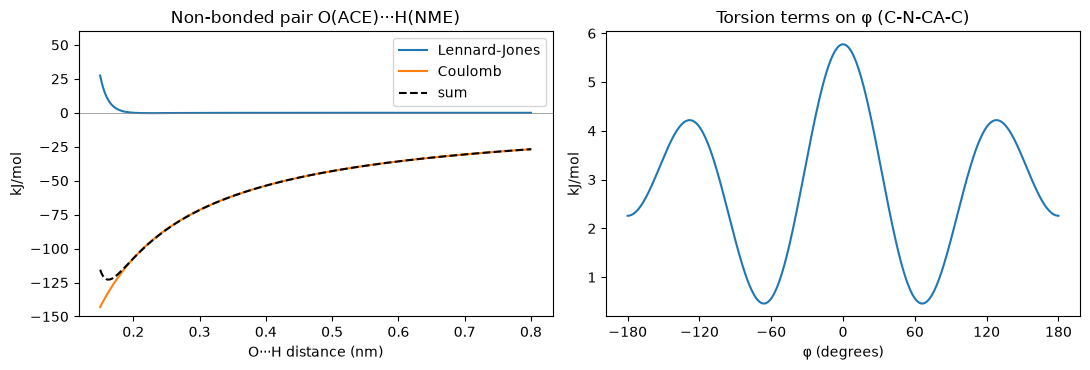

In [9]:
iO = int(atoms.query("residue == 'ACE' and atom == 'O'").idx.iloc[0])
iH = int(atoms.query("residue == 'NME' and atom == 'H'").idx.iloc[0])
r = np.linspace(0.15, 0.8, 300)
s_ij, e_ij = 0.5 * (sig[iO] + sig[iH]), np.sqrt(eps[iO] * eps[iH])

phi_atoms = [int(atoms.query("residue == @res and atom == @name").idx.iloc[0])
             for res, name in [("ACE", "C"), ("ALA", "N"), ("ALA", "CA"), ("ALA", "C")]]
grid = np.radians(np.arange(-180, 181))
E_phi = np.zeros_like(grid)
for t in range(tors.getNumTorsions()):
    i, j, k, l, n, phi0, kt = tors.getTorsionParameters(t)
    if [i, j, k, l] in (phi_atoms, phi_atoms[::-1]):
        E_phi += kt.value_in_unit(unit.kilojoule_per_mole) * (1 + np.cos(n * grid - phi0.value_in_unit(unit.radian)))
        print(f"phi term: n = {n}, phi0 = {np.degrees(phi0.value_in_unit(unit.radian)):.0f} deg, k = {kt.value_in_unit(unit.kilojoule_per_mole):.3f} kJ/mol")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(r, lj(r, s_ij, e_ij), label="Lennard-Jones")
ax[0].plot(r, ONE_4PI_EPS0 * q[iO] * q[iH] / r, label="Coulomb")
ax[0].plot(r, lj(r, s_ij, e_ij) + ONE_4PI_EPS0 * q[iO] * q[iH] / r, "k--", label="sum")
ax[0].set(ylim=(-150, 60), xlabel="O···H distance (nm)", ylabel="kJ/mol", title="Non-bonded pair O(ACE)···H(NME)")
ax[0].axhline(0, color="grey", lw=0.5); ax[0].legend()
ax[1].plot(np.degrees(grid), E_phi)
ax[1].set(xlabel="φ (degrees)", ylabel="kJ/mol", title="Torsion terms on φ (C-N-CA-C)", xticks=range(-180, 181, 60))
plt.tight_layout(); plt.show()

The Coulomb attraction between the negative O and positive H is much stronger than the Lennard-Jones term at
normal distances: that is a **hydrogen bond** in a classical force field. At short range the $r^{-12}$ wall
stops the atoms from overlapping. The torsion term on φ alone is small; the real φ/ψ preferences of a peptide
come from torsions *plus* all the non-bonded interactions they change, which is what Notebook 10 maps.

Other force fields (CHARMM36m, OPLS-AA, GAFF for drug-like molecules, OpenFF Sage) use the same terms with
small variations (CHARMM adds Urey–Bradley and CMAP terms). You will parameterize a drug with GAFF2 in Notebook 11.

### ✏️ Exercise 1

Which bond in the structure is furthest from its equilibrium length, and how much energy does it store?
Rebuild the bond table into a DataFrame and sort it.

In [10]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
df = pd.DataFrame(bond_rows, columns=["bond", "r", "r0", "k", "E"])
df["dev"] = (df.r - df.r0).abs()
df.sort_values("dev", ascending=False).head(3)
```

</details>

### ✏️ Exercise 2

**Minimize** the energy with `openmm.LocalEnergyMinimizer.minimize(context)` and print the energy of each term
before and after. Which terms changed most? (Reset the positions with `context.setPositions(X)` afterwards.)

In [11]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
def terms():
    return {type(f).__name__: round(context.getState(getEnergy=True, groups={i}).getPotentialEnergy()
            .value_in_unit(unit.kilojoule_per_mole), 3) for i, f in enumerate(system.getForces())}
context.setPositions(X); before = terms()
openmm.LocalEnergyMinimizer.minimize(context); after = terms()
print(pd.DataFrame({"before": before, "after": after}))
context.setPositions(X)
```

</details>

### ✏️ Exercise 3

Switch to a different force field, `amber99sbildn.xml`, and print the per-term energies for the same structure.
Are the bond energies the same? What about the torsions? (Hint: ff14SB and ff99SB-ILDN differ mainly in backbone and side-chain torsions.)

In [12]:
# Your code here

<details>
<summary><b>Show solution</b></summary>

```python
sys2 = app.ForceField("amber99sbildn.xml").createSystem(pdb.topology, nonbondedMethod=app.NoCutoff)
for i, f in enumerate(sys2.getForces()):
    f.setForceGroup(i)
ctx2 = openmm.Context(sys2, openmm.VerletIntegrator(0.001), openmm.Platform.getPlatformByName("Reference"))
ctx2.setPositions(X)
for i, f in enumerate(sys2.getForces()):
    print(type(f).__name__, round(ctx2.getState(getEnergy=True, groups={i}).getPotentialEnergy()._value, 3))
```

</details>

## Key takeaways

- A force field is a sum of bonds, angles, torsions, Lennard-Jones, and Coulomb terms with fitted parameters.
- OpenMM's `System` holds every parameter; you can read them and reproduce each energy exactly.
- 1-2 and 1-3 pairs are excluded and 1-4 pairs are scaled; harmonic terms in OpenMM carry a factor ½.
- Forces are the negative gradient of the energy; MD only ever needs these forces.

**Next:** [03 · Integrators, timestep, and energy conservation](03_integrators_timestep.ipynb).